# Music Recognition with Audio Fingerprints

A radio station must report every song it played, and the presenter often talks over the beginning
and the end of a song. A music fan who holds a phone towards a loudspeaker in a noisy bar has the
same problem: identify one exact recording among millions from a few seconds of distorted sound.
This notebook follows the book section *Audio Fingerprinting* and the method that Wang (2003)
published for Shazam: spectrogram, constellation map, combinatorial hashing, query fingerprint, and
matching with an offset histogram. A catalogue of four music recordings carries the numbers of the
book through all steps. At the end, we monitor a short broadcast and write its play list.

**Learning goals:**
- Extract the constellation map of a recording and see which peaks survive noise
- Pair peaks into hashes and store them in an inverted file
- Match a query with an offset histogram and read the score
- Identify a song under a voice that talks over it, and see where the method breaks
- Turn window-by-window matches into the play list of a broadcast

**Prerequisites:** demo ch11-01 (spectrogram); inverted files (chapter 4)

**Data:** four music recordings and two LibriVox readings of the chapter (librosa examples,
downloaded on the first run). No model is needed; the notebook runs in under a minute.

## Setup

In [1]:
import warnings
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
import librosa
warnings.filterwarnings("ignore", category=FutureWarning, module="librosa")   # deprecation notes of time_stretch
from scipy.ndimage import maximum_filter
from scipy.signal import butter, sosfilt
from IPython.display import Audio

from shared.display import print_table, display_md
from ch11_audio import CLIPS, MUSIC_C, SPEECH_C, load, credits

FS, N, HOP = 11025, 1024, 256                           # 93 ms frames, hop 23.2 ms, as in the book
FRAME_S = HOP / FS
CATALOGUE = ["brahms", "nutcracker", "vibeace", "trumpet"]
songs = {n: load(n, FS) for n in CATALOGUE}             # resampled to 11,025 Hz

## 1. Spectrogram and Constellation Map

Noise spreads its energy over many frequencies and frames, while instruments and voices concentrate
theirs in strong, localized peaks. A point of the spectrogram becomes a peak if its energy is the
maximum within a neighborhood of 15 bins by 15 frames (about 160 Hz by 350 ms) and lies less than
50 dB below the strongest point of the recording. Everything else is discarded.

In [2]:
def spectrogram_db(y):
    S = np.abs(librosa.stft(y, n_fft=N, hop_length=HOP)) ** 2          # 513 bins x frames
    return 10 * np.log10(S / S.max() + 1e-12)                          # dB below the strongest point

def constellation(y, neighborhood=(15, 15), floor_db=-50):
    """Peaks as two arrays (frame t, bin f), sorted by time."""
    S = spectrogram_db(y)
    is_peak = (S == maximum_filter(S, size=neighborhood)) & (S > floor_db)
    f, t = np.nonzero(is_peak)
    order = np.argsort(t, kind="stable")
    return t[order], f[order]

peaks = {n: constellation(y) for n, y in songs.items()}
print_table([[CLIPS[n][0], f"{len(y) / FS:.1f} s", len(peaks[n][0]), f"{len(peaks[n][0]) / (len(y) / FS):.1f}"]
             for n, y in songs.items()],
            headers=["Recording", "Duration", "Peaks", "Peaks per second"])

| Recording                                  | Duration   |   Peaks |   Peaks per second |
|:-------------------------------------------|:-----------|--------:|-------------------:|
| Brahms, Hungarian Dance No. 5              | 45.8 s     |    2317 |               50.5 |
| Tchaikovsky, Dance of the Sugar Plum Fairy | 119.9 s    |    6353 |               53   |
| Vibe Ace (jazz)                            | 61.5 s     |    2329 |               37.9 |
| Trumpet loop (90 bpm)                      | 5.3 s      |     138 |               25.9 |

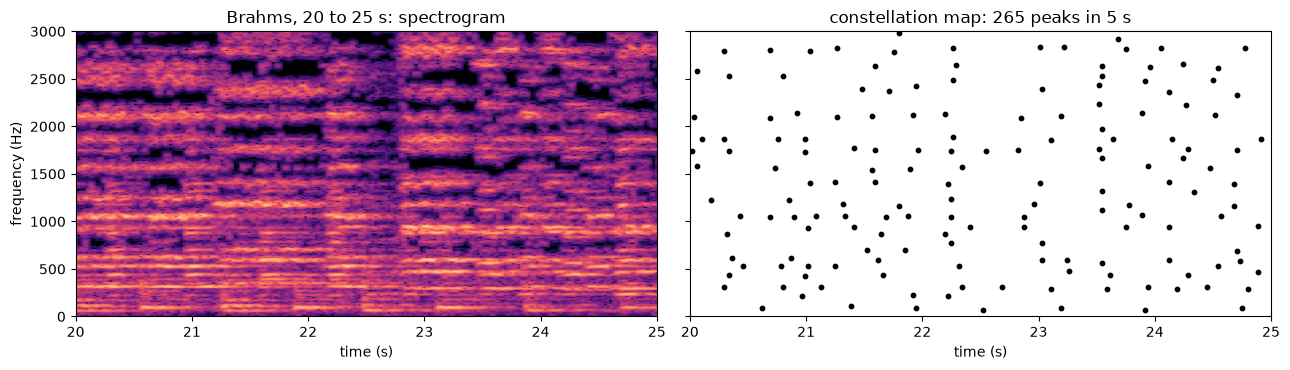

In [3]:
a, b = 20, 25                                           # five seconds of the Brahms clip
S = spectrogram_db(songs["brahms"])
t, f = peaks["brahms"]
sel = (t >= a / FRAME_S) & (t < b / FRAME_S)
extent = (0, S.shape[1] * FRAME_S, 0, FS / 2)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
a1.imshow(S, origin="lower", aspect="auto", cmap="magma", vmin=-80, vmax=0, extent=extent)
a1.set(xlim=(a, b), ylim=(0, 3000), xlabel="time (s)", ylabel="frequency (Hz)", title="Brahms, 20 to 25 s: spectrogram")
a2.scatter(t[sel] * FRAME_S, f[sel] * FS / N, s=10, color="black")
a2.set(xlim=(a, b), xlabel="time (s)", title=f"constellation map: {sel.sum()} peaks in 5 s")
fig.tight_layout()
plt.show()

### Which peaks survive noise?

We add white noise to a 10-second excerpt at signal-to-noise ratios from 20 dB down to 0 dB, where
noise and music have the same energy, and count how many peaks of the clean excerpt are found again,
at the same point or one bin or frame away.

In [4]:
excerpt = songs["brahms"][20 * FS:30 * FS]
clean = set(zip(*constellation(excerpt)))
rng = np.random.default_rng(0)

def add_noise(y, snr_db):
    noise = rng.standard_normal(len(y))
    return y + noise * np.sqrt(np.mean(y ** 2) / (np.mean(noise ** 2) * 10 ** (snr_db / 10)))

rows, noisy_peaks = [], {}
for snr in (20, 10, 5, 0):
    noisy_peaks[snr] = set(zip(*constellation(add_noise(excerpt, snr))))
    near = sum(any((ti + dt, fi + df) in noisy_peaks[snr] for dt in (-1, 0, 1) for df in (-1, 0, 1)) for ti, fi in clean)
    rows.append([f"{snr} dB", len(noisy_peaks[snr]), f"{len(clean & noisy_peaks[snr]) / len(clean):.0%}", f"{near / len(clean):.0%}"])
print_table(rows, headers=[f"Noise (clean: {len(clean)} peaks)", "Peaks", "Same point", "Within one bin or frame"])

| Noise (clean: 457 peaks)   |   Peaks | Same point   | Within one bin or frame   |
|:---------------------------|--------:|:-------------|:--------------------------|
| 20 dB                      |     601 | 71%          | 82%                       |
| 10 dB                      |     717 | 48%          | 61%                       |
| 5 dB                       |     801 | 37%          | 54%                       |
| 0 dB                       |     817 | 24%          | 38%                       |

The noise adds peaks of its own and moves or removes many of the music's peaks. The method does not
need them all: as the matching step will show, a fraction is enough.

## 2. Combinatorial Hashing

A single peak is a weak fingerprint: its bin takes one of 513 values, so it matches thousands of
peaks in a large catalogue by chance. Each peak therefore serves as an anchor and is paired with up
to 5 peaks in a target zone in front of it: between 1 and 64 frames later (23 ms to 1.5 s) and within
64 bins (690 Hz) above or below. Each pair becomes a hash of three values, stored with the anchor
time $t_1$:

$$
h = \bigl(f_1,\ f_2,\ t_2 - t_1\bigr)
$$

In [5]:
def hashes(t, f, fan_out=5, dt_max=64, df_max=64):
    """List of (hash, anchor time); the hash is (f1, f2, dt)."""
    out = []
    for i in range(len(t)):
        n = 0
        for j in range(i + 1, len(t)):
            dt = t[j] - t[i]
            if dt > dt_max:
                break                                    # peaks are sorted by time
            if dt < 1 or abs(int(f[j]) - int(f[i])) > df_max:
                continue
            out.append(((int(f[i]), int(f[j]), int(dt)), int(t[i])))
            n += 1
            if n == fan_out:
                break
    return out

pack = lambda h: (h[0] << 16) | (h[1] << 6) | (h[2] - 1)   # 10 + 10 + 6 bits (dt - 1 < 64) fit into 32 bits

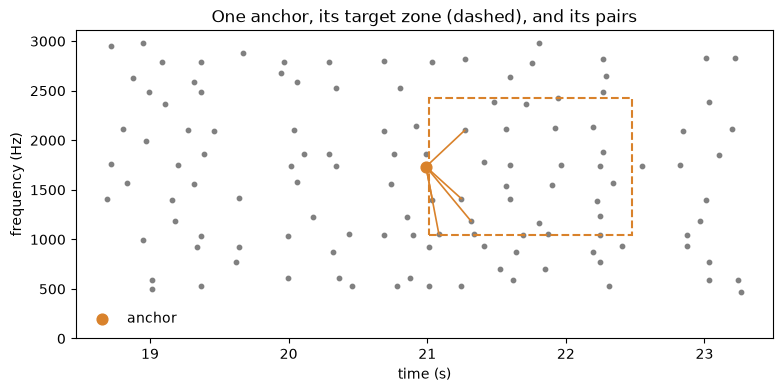

| Hash (f1, f2, dt)   |   Packed into 32 bits | Anchor time t1   |
|:--------------------|----------------------:|:-----------------|
| (161, 130, 2)       |            10,559,617 | 20.99 s          |
| (161, 98, 4)        |            10,557,571 | 20.99 s          |
| (161, 131, 11)      |            10,559,690 | 20.99 s          |
| (161, 195, 12)      |            10,563,787 | 20.99 s          |
| (161, 110, 14)      |            10,558,349 | 20.99 s          |

In [6]:
t, f = peaks["brahms"]
i = int(np.argmin(np.abs(t * FRAME_S - 21.0) + (f < 70) * 100))     # an anchor near 21 s, above 750 Hz
pairs = [(h, ta) for h, ta in hashes(t, f) if ta == t[i] and h[0] == f[i]]

fig, ax = plt.subplots(figsize=(9, 4))
near = (np.abs(t - t[i]) < 100) & (np.abs(f.astype(int) - int(f[i])) < 120)
ax.scatter(t[near] * FRAME_S, f[near] * FS / N, s=10, color="gray")
ax.add_patch(plt.Rectangle(((t[i] + 1) * FRAME_S, (f[i] - 64) * FS / N), 63 * FRAME_S, 128 * FS / N,
                           fill=False, ec=MUSIC_C, lw=1.5, ls="--"))
for (f1, f2, dt), ta in pairs:
    ax.plot([ta * FRAME_S, (ta + dt) * FRAME_S], [f1 * FS / N, f2 * FS / N], color=MUSIC_C, lw=1.2)
ax.scatter([t[i] * FRAME_S], [f[i] * FS / N], s=60, color=MUSIC_C, zorder=3, label="anchor")
ax.set(xlabel="time (s)", ylabel="frequency (Hz)", ylim=(0, None), title="One anchor, its target zone (dashed), and its pairs")
ax.legend(frameon=False)
plt.show()

print_table([[f"({f1}, {f2}, {dt})", f"{pack((f1, f2, dt)):,}", f"{ta * FRAME_S:.2f} s"] for (f1, f2, dt), ta in pairs],
            headers=["Hash (f1, f2, dt)", "Packed into 32 bits", "Anchor time t1"])

The anchor is paired with the first five peaks in its zone, so most of its pairs span short time
distances. The hashes of all catalogued recordings form an inverted file: the hash plays the role of the term,
and its postings list holds the recordings and anchor times in which it occurs.

In [7]:
index = defaultdict(list)                               # hash -> [(recording, anchor time), ...]
n_hashes = {}
for n in CATALOGUE:
    hs = hashes(*peaks[n])
    n_hashes[n] = len(hs)
    for h, ta in hs:
        index[h].append((n, ta))

possible = 513 * 129 * 64
display_md(
    "| | Value |\n|---|---|\n"
    + "".join(f"| hashes of {CLIPS[n][0]} | {n_hashes[n]:,} ({n_hashes[n] / len(peaks[n][0]):.1f} per peak) |\n" for n in CATALOGUE)
    + f"| postings in the index | {sum(len(v) for v in index.values()):,} |\n"
    f"| distinct hashes | {len(index):,} |\n"
    f"| possible hashes (513 x 129 x 64) | {possible:,} |"
)

| | Value |
|---|---|
| hashes of Brahms, Hungarian Dance No. 5 | 11,471 (5.0 per peak) |
| hashes of Tchaikovsky, Dance of the Sugar Plum Fairy | 31,549 (5.0 per peak) |
| hashes of Vibe Ace (jazz) | 11,481 (4.9 per peak) |
| hashes of Trumpet loop (90 bpm) | 624 (4.5 per peak) |
| postings in the index | 55,125 |
| distinct hashes | 45,751 |
| possible hashes (513 x 129 x 64) | 4,235,328 |

Most of the 4.2 million possible hashes never occur, and those that occur do so once or a few
times: a postings list is short.

## 3. Query Fingerprint and Matching

The query is processed exactly like the catalogue. Each query hash is looked up in the index. If
the query comes from recording $s$ and starts at position $\delta$ in it, every correctly matched
hash satisfies $t_s - t_q = \delta$; chance matches have arbitrary differences. The score of a
recording is the height of the tallest bin of its offset histogram:

$$
\text{score}(s) = \max_{\delta}\ \Bigl|\bigl\{(h, t_q, t_s) : h \text{ matches},\ t_s - t_q = \delta \bigr\}\Bigr|
$$

In [8]:
def match(query):
    """Per recording: the matched (t_q, t_s) pairs and the offset histogram."""
    pairs, hist = defaultdict(list), defaultdict(Counter)
    for h, tq in hashes(*constellation(query)):
        for n, ts in index.get(h, ()):
            pairs[n].append((tq, ts))
            hist[n][ts - tq] += 1
    return pairs, hist

def report(query, label):
    pairs, hist = match(query)
    rows = []
    for n in sorted(hist, key=lambda n: -hist[n].most_common(1)[0][1]):
        delta, votes = hist[n].most_common(1)[0]
        rows.append([label, CLIPS[n][0], len(pairs[n]), votes, f"{delta * FRAME_S:.2f} s"])
        label = ""
    return rows, pairs, hist

The book's query is a 10-second excerpt of the Brahms clip from 20 seconds on. In the hard version, a
LibriVox reading is mixed in at the same energy as the music (0 dB), as when a presenter speaks over
a song, and the mixture is limited to the telephone band of 300 to 3400 Hz.

In [9]:
voice = load("libri2", FS)[:len(excerpt)]
phone = butter(4, [300, 3400], btype="bandpass", fs=FS, output="sos")

def talk_over(music, voice, snr_db):
    gain = np.sqrt(np.mean(music ** 2) / (np.mean(voice ** 2) * 10 ** (snr_db / 10)))
    return sosfilt(phone, music + gain * voice)

hard = talk_over(excerpt, voice, 0)
rows_clean, pairs_clean, hist_clean = report(excerpt, f"clean, {len(hashes(*constellation(excerpt))):,} hashes")
rows_hard, pairs_hard, hist_hard = report(hard, f"talk over, phone band, {len(hashes(*constellation(hard))):,} hashes")
print_table(rows_clean + rows_hard, headers=["Query", "Recording", "Matched hashes", "Tallest bin", "at offset"])
display_md("Listen to the hard query:")
Audio(hard, rate=FS)

| Query                               | Recording                                  |   Matched hashes |   Tallest bin | at offset   |
|:------------------------------------|:-------------------------------------------|-----------------:|--------------:|:------------|
| clean, 2,182 hashes                 | Brahms, Hungarian Dance No. 5              |              967 |           768 | 19.99 s     |
|                                     | Tchaikovsky, Dance of the Sugar Plum Fairy |              127 |             3 | 46.74 s     |
|                                     | Vibe Ace (jazz)                            |               33 |             2 | 5.62 s      |
|                                     | Trumpet loop (90 bpm)                      |                1 |             1 | -8.17 s     |
| talk over, phone band, 2,232 hashes | Brahms, Hungarian Dance No. 5              |              286 |           201 | 19.99 s     |
|                                     | Tchaikovsky, Dance of the Sugar Plum Fairy |              174 |             3 | 54.52 s     |
|                                     | Vibe Ace (jazz)                            |               36 |             2 | 26.73 s     |
|                                     | Trumpet loop (90 bpm)                      |                1 |             1 | 1.07 s      |

Listen to the hard query:

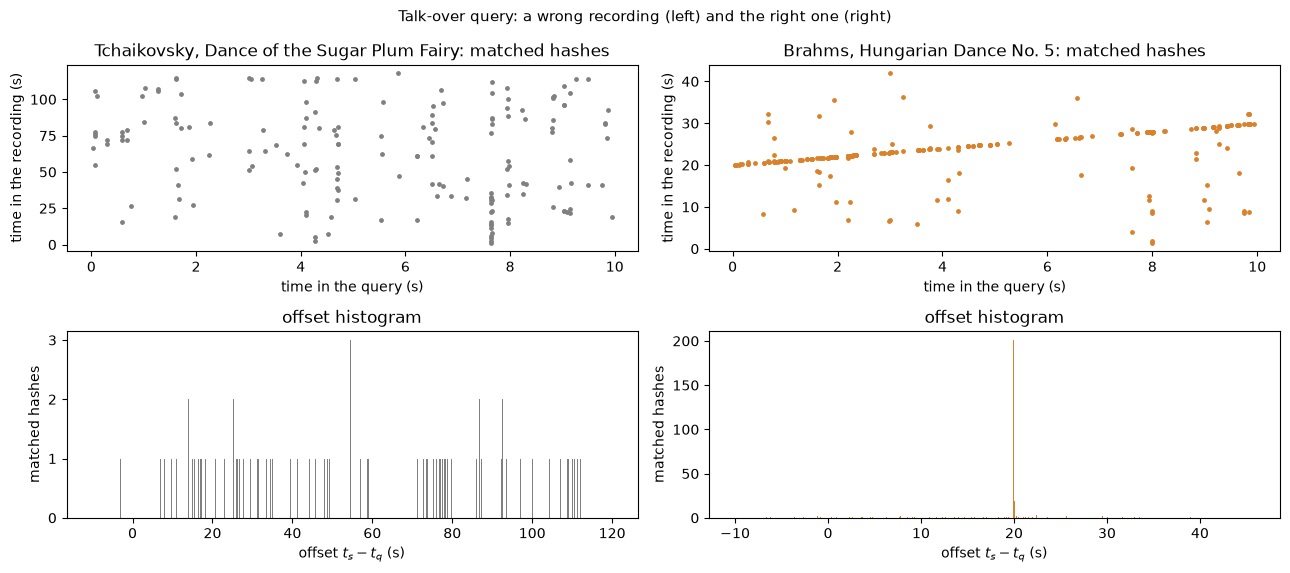

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 5.8))
for col, n in enumerate(("nutcracker", "brahms")):
    tq, ts = np.array(pairs_hard[n]).T
    axes[0, col].scatter(tq * FRAME_S, ts * FRAME_S, s=6, color=MUSIC_C if n == "brahms" else "gray")
    axes[0, col].set(xlabel="time in the query (s)", ylabel="time in the recording (s)",
                     title=f"{CLIPS[n][0]}: matched hashes")
    axes[1, col].hist((ts - tq) * FRAME_S, bins=np.arange(-10, len(songs[n]) / FS, FRAME_S * 4),
                      color=MUSIC_C if n == "brahms" else "gray")
    axes[1, col].set(xlabel="offset $t_s - t_q$ (s)", ylabel="matched hashes", title="offset histogram")
fig.suptitle("Talk-over query: a wrong recording (left) and the right one (right)", fontsize=11)
fig.tight_layout()
plt.show()

For the wrong recording, the matched hashes are scattered and the histogram is flat. For the right
one, the matches line up on a diagonal, and the histogram has one sharp peak at the position of the
excerpt. The voice destroys most hashes of the music, but the aligned ones still outnumber the best
wrong recording by far. Counting matched hashes alone would give a much closer race: the long
Tchaikovsky clip collects many chance matches, but they spread over many offsets.

In [11]:
delta, votes = hist_clean["brahms"].most_common(1)[0]
display_md(
    f"Even the clean excerpt agrees on the offset with only **{votes:,} of its "
    f"{len(hashes(*constellation(excerpt))):,} hashes**. The excerpt starts at sample {20 * FS:,}, which is "
    f"{20 / FRAME_S:.1f} frames, so its frames are shifted by a fraction of a hop against those of the "
    f"catalogue. Some peaks move to a neighboring bin or frame, and their hashes change."
)

Even the clean excerpt agrees on the offset with only **768 of its 2,182 hashes**. The excerpt starts at sample 220,500, which is 861.3 frames, so its frames are shifted by a fraction of a hop against those of the catalogue. Some peaks move to a neighboring bin or frame, and their hashes change.

How loud can the voice get?

In [12]:
rows = []
for snr in (0, -5, -10, -15):
    _, hist = match(talk_over(excerpt, voice, snr))
    ranked = sorted(((c.most_common(1)[0][1], n) for n, c in hist.items()), reverse=True)
    rows.append([f"voice {-snr} dB louder than the music" if snr else "voice as loud as the music",
                 ranked[0][0] if ranked[0][1] == "brahms" else 0, max(v for v, n in ranked if n != "brahms")])
print_table(rows, headers=["Talk-over query, phone band", "Brahms: tallest bin", "Best wrong recording"])

| Talk-over query, phone band       |   Brahms: tallest bin |   Best wrong recording |
|:----------------------------------|----------------------:|-----------------------:|
| voice as loud as the music        |                   201 |                      3 |
| voice 5 dB louder than the music  |                   130 |                      3 |
| voice 10 dB louder than the music |                    76 |                      2 |
| voice 15 dB louder than the music |                    48 |                      2 |

## 4. Limits: Speed and Pitch

The fingerprint matches recordings, not songs. A change of pitch moves all frequencies, and a change
of speed stretches all time distances, so the hashes no longer match. We shift the clean excerpt by
half a semitone and one semitone, and play it 2% and 5% faster.

In [13]:
variants = {
    "pitch +0.5 semitone": librosa.effects.pitch_shift(excerpt, sr=FS, n_steps=0.5),
    "pitch +1 semitone": librosa.effects.pitch_shift(excerpt, sr=FS, n_steps=1),
    "2% faster": librosa.effects.time_stretch(excerpt, rate=1.02),
    "5% faster": librosa.effects.time_stretch(excerpt, rate=1.05),
}
rows = [["unchanged", hist_clean["brahms"].most_common(1)[0][1],
         max(c.most_common(1)[0][1] for n, c in hist_clean.items() if n != "brahms")]]
for name, q in variants.items():
    _, hist = match(q)
    rows.append([name, hist["brahms"].most_common(1)[0][1] if "brahms" in hist else 0,
                 max((c.most_common(1)[0][1] for n, c in hist.items() if n != "brahms"), default=0)])
print_table(rows, headers=["Query (Brahms excerpt)", "Brahms: tallest bin", "Best wrong recording"])

| Query (Brahms excerpt)   |   Brahms: tallest bin |   Best wrong recording |
|:-------------------------|----------------------:|-----------------------:|
| unchanged                |                   768 |                      3 |
| pitch +0.5 semitone      |                     1 |                      3 |
| pitch +1 semitone        |                     3 |                      4 |
| 2% faster                |                    94 |                      2 |
| 5% faster                |                    30 |                      3 |

Half a semitone is enough to lose the recording. A small speed change leaves the short time
distances of many pairs intact, so a few percent still match, with far fewer votes. A live
performance, a cover version, or someone singing the melody produce different peaks altogether;
robust variants quantize the hash values more coarsely or search over several stretch factors, at
the cost of more chance matches.

## Payoff: Writing the Play List of a Broadcast

The radio station needs the play list for its royalty report. A short broadcast joins a reading, 20
seconds of Tchaikovsky with the presenter talking over its first 6 seconds, a second reading, and 20
seconds of Vibe Ace. The monitor fingerprints the stream in windows of 5 seconds with a hop of 2.5
seconds. A window counts as a match if its tallest bin has at least 20 votes and at least five
times the votes of the next recording.

In [14]:
tchaikovsky = songs["nutcracker"][30 * FS:50 * FS].copy()
presenter = load("libri2", FS)[:6 * FS]
tchaikovsky[:6 * FS] += presenter * np.sqrt(np.mean(tchaikovsky[:6 * FS] ** 2) / np.mean(presenter ** 2))
parts = [("talk", load("libri1", FS)), ("nutcracker", tchaikovsky), ("talk", load("libri3", FS)),
         ("vibeace", songs["vibeace"][10 * FS:30 * FS])]
stream = np.concatenate([p for _, p in parts])
starts = np.cumsum([0] + [len(p) / FS for _, p in parts])
display_md("True schedule: " + "; ".join(f"{name} {s:.1f} to {e:.1f} s" for (name, _), s, e in zip(parts, starts, starts[1:])))

True schedule: talk 0.0 to 14.8 s; nutcracker 14.8 to 34.8 s; talk 34.8 to 48.8 s; vibeace 48.8 to 68.8 s

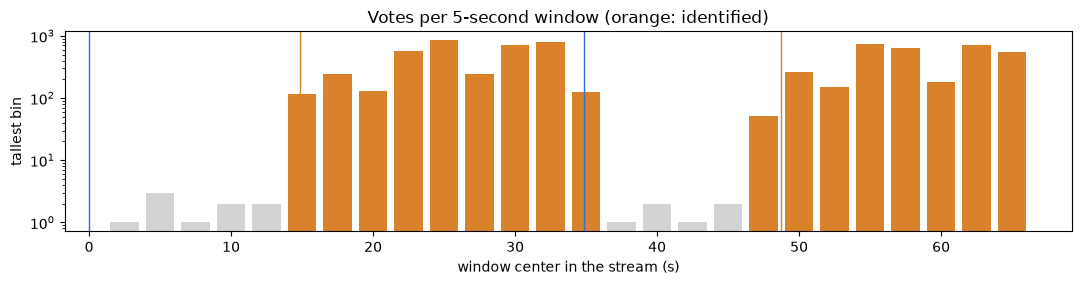

In [15]:
W, H = 5.0, 2.5
windows = []
for a in np.arange(0, len(stream) / FS - W + 1e-9, H):
    _, hist = match(stream[int(a * FS):int((a + W) * FS)])
    ranked = sorted(((c.most_common(1)[0][1], n, c.most_common(1)[0][0]) for n, c in hist.items()), reverse=True)
    votes, name, delta = ranked[0] if ranked else (0, None, 0)
    second = ranked[1][0] if len(ranked) > 1 else 0
    ok = votes >= 20 and votes >= 5 * max(second, 1)
    windows.append((a, name if ok else None, votes, delta * FRAME_S - a))   # shift: recording time - stream time

fig, ax = plt.subplots(figsize=(13, 2.6))
ax.bar([w[0] + W / 2 for w in windows], [w[2] for w in windows], width=H * 0.8,
       color=[MUSIC_C if w[1] else "lightgray" for w in windows])
for (name, _), s in zip(parts, starts):
    ax.axvline(s, color=SPEECH_C if name == "talk" else MUSIC_C, lw=1)
ax.set(yscale="log", xlabel="window center in the stream (s)", ylabel="tallest bin", title="Votes per 5-second window (orange: identified)")
plt.show()

In [16]:
playlist = []
for a, name, votes, shift in windows:
    if name and playlist and playlist[-1]["name"] == name:
        playlist[-1]["end"] = a + W
    elif name:
        playlist.append({"name": name, "start": a, "end": a + W, "shift": shift})
print_table([[CLIPS[p["name"]][0], f"{p['start']:.1f} to {p['end']:.1f} s", f"{p['shift']:+.2f} s"] for p in playlist],
            headers=["Recording", "Identified in the windows", "Shift: recording time minus stream time"])

| Recording                                  | Identified in the windows   | Shift: recording time minus stream time   |
|:-------------------------------------------|:----------------------------|:------------------------------------------|
| Tchaikovsky, Dance of the Sugar Plum Fairy | 12.5 to 37.5 s              | +15.15 s                                  |
| Vibe Ace (jazz)                            | 45.0 to 67.5 s              | -38.75 s                                  |

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">A fingerprint is a hash lookup with an alignment check</strong><br>
Both songs are identified, the talked-over intro included, and no reading is mistaken for music. The constant shift says which part of the recording was aired: Tchaikovsky's music starts in the stream at 14.8 s, and $14.8 + 15.15 \approx 30$ s is where the excerpt was cut from the recording. The lookup never compares the query with the recordings themselves; its work grows with the number of matched postings, not with the size of the catalogue.
</div>

## Summary

- The constellation map keeps only the strongest local peaks of the spectrogram. Noise moves or
  removes many of them, but enough survive.
- Pairs of peaks become hashes $(f_1, f_2, t_2 - t_1)$ without absolute time, stored in an
  inverted file with the recording and the anchor time.
- The offset histogram is the decisive test: correct matches agree on one offset, chance matches
  scatter. Its tallest bin is the score, its position the place of the query in the recording.
- The method identifies recordings, not songs: a shift of half a semitone already breaks it.

## Try it yourself

1. **Fewer peaks.** Use a neighborhood of `(25, 25)` or a floor of `-40` dB in `constellation`,
   rebuild the index, and rerun the talk-over query. How do the votes change?
2. **Shorter queries.** Query the hard version with 3 seconds and with 1 second of the excerpt. From
   which length on does Brahms still win clearly?
3. **A new song.** Add `"libri1"` to the catalogue as if it were a song and monitor the broadcast
   again. Is the first reading now found, and is the second one mistaken for it?

## Credits

In [17]:
print_table(credits(CATALOGUE + ["libri1", "libri2", "libri3"]), headers=["Clip", "Title", "Attribution", "License"])

| Clip       | Title                                                                  | Attribution                                             | License    |
|:-----------|:-----------------------------------------------------------------------|:--------------------------------------------------------|:-----------|
| brahms     | Hungarian Dance number 5                                               | Johannes Brahms (composer), US Army Strings (performer) | CC-PDM-1.0 |
| nutcracker | Dance of the Sugar Plum Fairy                                          | P.I. Tchaikovsky (composer), Kevin MacLeod (arranger)   | CC-BY-4.0  |
| vibeace    | Vibe Ace                                                               | Kevin MacLeod                                           | CC-BY-4.0  |
| trumpet    | solo trumpet 06                                                        | Mihai Sorohan                                           | CC-BY-4.0  |
| libri1     | The Ashiel Mystery                                                     | Marion Bryce (author), Garth Comira (reader)            | CC-BY-4.0  |
| libri2     | The Age of Chivalry, chapter IX: The Adventure of the Cart             | Thomas Bulfinch (author), Anders Lankford (reader)      | CC-BY-4.0  |
| libri3     | Northanger Abbey (librosa metadata: Sense and Sensibility, chapter 18) | Jane Austen (author), Heather Barnett (reader)          | CC-BY-4.0  |